## **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
#### Tecnológico de Monterrey
#### Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Sistemas de Recomendación basados en factorización SVD y Agentes**

**Esta Actividad deberá resolverse de manera individual.**

* **Nombre:** Lucia Alvarez Irigoyen

* **Matrícula:**  A01840750



**Incluye todas las librerías y líneas de código que consideres adecuadas.**

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import sparse, linalg
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

RANDOM_STATE = 42

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
DIR = "/content/drive/My Drive/Colab Notebooks/2do trimestre/Semana 8"
os.chdir(DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Ejercicio - 1: cargando datos**
`README` establece separador `::`, codificación histórica compatible con `latin-1`, ratings enteros del 1 al 5 y esquemas de las tres fuentes. Hay 177 títulos sin ninguna evaluación; por ello el catálogo completo y las películas calificadas tienen tamaños distintos.

In [3]:
ratings = pd.read_csv('ratings.dat', sep='::', engine='python', encoding='latin-1',
                      names=['user_id','movie_id','rating','timestamp'])
movies = pd.read_csv('movies.dat', sep='::', engine='python', encoding='latin-1',
                     names=['movie_id','title','genres'])
users = pd.read_csv('users.dat', sep='::', engine='python', encoding='latin-1',
                    names=['user_id','gender','age','occupation','zipcode'])
# a) Obtener la cantidad exacta de usuarios, peliculas y evaluaciones
print('Usuarios:', users.user_id.nunique())
print('Películas en catálogo:', movies.movie_id.nunique())
print('Películas con ratings:', ratings.movie_id.nunique())
print('Evaluaciones:', len(ratings))
print("Escala:", *sorted(ratings["rating"].unique()), sep=", ")
print('Duplicados usuario-película:', ratings.duplicated(['user_id','movie_id']).sum())
display(movies.head(3), users.head(3), ratings.head(3))

Usuarios: 6040
Películas en catálogo: 3883
Películas con ratings: 3706
Evaluaciones: 1000209
Escala:, 1, 2, 3, 4, 5
Duplicados usuario-película: 0


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


,user_id,gender,age,occupation,zipcode
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


# **Ejercicio - 2: matriz de utilidad**

In [4]:
# 1. Obtener los identificadores de peliculas de la columna movie_id del df movies y convertirlos en un arreglo de NumPy.
movie_ids = movies.movie_id.to_numpy()
# 2. Obtener los identificadores únicos de usuarios y ordenarlos de menor a mayor.
user_ids = np.sort(users.user_id.unique())
# 2. Crear los renglones de la matriz, en donde el numero de filas puede ser menor al numero de movie_id disponibles
# Si los ids no son consecutivos, los renglones quedan compactos en posiciones consecutivas.
movie_to_row = pd.Series(np.arange(len(movie_ids)), index=movie_ids)
# 3. Crear las columnas de la matriz con los ids de los usuarios de forma consecutiva, aunque user_id no sea consecutivo
user_to_col = pd.Series(np.arange(len(user_ids)), index=user_ids)
# 4. En M se convierten los identificadores movie_id de 'ratings' en las posiciones de renglones de la nueva matriz
M = ratings.movie_id.map(movie_to_row).to_numpy()
# 5. En U se convierten los identificadores user_id de 'ratings' en las posiciones de columnas de la nueva matriz
U = ratings.user_id.map(user_to_col).to_numpy()
# 6. En Y se obtienen las calificaciones de 'ratings' y se convierten en un arreglo.
Y = ratings.rating.to_numpy(dtype=np.float32)
# 7. Se define el tamaño de la matriz con la cantidad de renglones por movie_ids y de columnas con user_ids
n_movies, n_users = len(movie_ids), len(user_ids)

# 2a. Obtener la dimensión y el grado de dispersión sparcity o densidad de dicha matriz
# Matriz de utilidad orientada a películas para extraer factores latentes de películas.
# La matriz se define como Matriz[M[i],U[i]] = Y[i]
matriz_utilidad = sparse.csr_matrix((Y, (M, U)), shape=(n_movies, n_users))
# Densidad = numero de evaluaciones non-zero (nnz) / numero total de posiciones (renglones * columnas)
densidad = matriz_utilidad.nnz / (n_movies*n_users)
print('Dimensiones:', matriz_utilidad.shape)
print('Densidad: %.2f%%' % (densidad*100))
print('Dispersión: %.2f%%' % ((1-densidad)*100))
# Calcular cuanta memoria se necesitaria si almacenaramos la matriz completa (no es el peso de CSR)
print('Espacio denso float32 aproximado: %.1f MB' % (n_movies*n_users*4/1e6))

Dimensiones: (3883, 6040)
Densidad: 4.26%
Dispersión: 95.74%
Espacio denso float32 aproximado: 93.8 MB


Se construye en orientación **películas × usuarios** para que la descomposición genere vectores de películas. Tamaño: 3,883 × 6,040; densidad 4.26468%; dispersión 95.73532%. Se usa `csr_matrix` porque más de 95% de los pares no tienen evaluación, lo cual ahorra memoria. No interpretamos los ceros como "dislikes" / "no me gusta".

#### **2b.  En particular, ¿qué te dice el valor de dispersión obtenida?**
Significa que desconocemos la mayoría de las preferencias posibles entre usuarios y películas (~95%). Por ejemplo, que un usuario no haya evaluado Titanic no significa que no le guste. Simplemente no tenemos información. Esta distinción es fundamental porque los valores faltantes no deben interpretarse como calificaciones de cero estrellas.

### **2c. ¿Qué implicaciones computacionales o consideraciones tienen que tomarse en cuenta al trabajar con matrices altamente dispersas?**
Una matriz altamente dispersa puede generar problemas de memoria, procesamiento y aprendizaje. Si almacenáramos todas las posiciones de una matriz muy grande, utilizaríamos memoria para representar millones de valores desconocidos. Además, las películas con pocas evaluaciones proporcionan menos información para aprender patrones confiables. Por eso utilizamos matrices dispersas con sparse.csr_matrix(), reducimos dimensionalidad y evaluamos los modelos con datos separados.

En este caso, esto es conveniente porque aproximadamente el 95.74% de las combinaciones entre películas y usuarios no tienen evaluaciones.

En lugar de almacenar explícitamente millones de ceros, CSR almacena principalmente los valores existentes y la información necesaria para localizarlos.

# **Ejercicio - 3: varianza explicada y número de componentes latentes**

Componentes necesarios: {0.8: 709, 0.9: 1082, 0.95: 1440}


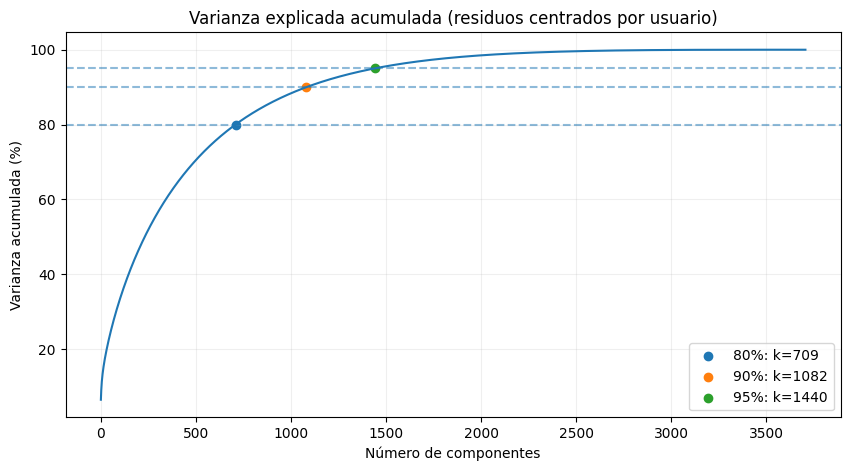

In [5]:
# Centrado por usuario sobre ratings observados.
# Los valores ausentes siguen con valor 0 en la matriz dispersa.
# 1. Realizar un conteo de cuantas peliculas ha evaluado cada usuario.
cuenta_usuario = np.bincount(U, minlength=n_users)
# 2. Realizar la suma de las calificaciones que ha otorgado cada usuario.
suma_usuario = np.bincount(U, weights=Y, minlength=n_users)
# 3. La media se calcula como la suma dividido por el numero total de evaluaciones de los usuarios.
# Con esto conocemos la tendencia de cada usuario y las diferencias en escala entre usuarios.
media_usuario_full = suma_usuario / cuenta_usuario
# En esta matriz se guardan las calificaciones centradas respecto al promedio de cada usuario.
X = sparse.csr_matrix((Y-media_usuario_full[U], (M,U)), shape=(n_movies,n_users))
# Identificar las filas correspondientes a peliculas que tienen evaluaciones almacenadas en la matriz.
activas = np.flatnonzero(X.getnnz(axis=1)>0)

# Crear una matriz llamada gram para identificar los valores propios de X @ X.T
# EStos equivalen a valores singulares al cuadrado.
gram = (X[activas].astype(np.float64) @ X[activas].astype(np.float64).T).toarray()
eigenvalores = linalg.eigh(gram, eigvals_only=True, overwrite_a=True,
                           check_finite=False, driver='evr')[::-1]
# Calculas los valores propios de la matriz de Gram y ordernarlos de mayor a menor
# Cuanto mayor sea el valor propio de un componente, mayor es su contribución a
# la energía espectral de la matriz.
# Limitar los valores del arreglo a un intervalo y sin valores negativos.
eigenvalores = np.clip(eigenvalores, 0, None)
# Calcular varianza acumulada, para determinar que porcentaje de la energia
# espectral total conservamos conforme agregamos componentes.
varianza_acum = np.cumsum(eigenvalores)/eigenvalores.sum()
# Calcular cuantos componentes necesitamos para cada porcentaje 80, 90 y 95.
umbrales = {porcentaje:int(np.searchsorted(varianza_acum, porcentaje)+1)
            for porcentaje in (0.80,0.90,0.95)}
print('Componentes necesarios:', umbrales)

# 3a. Crear la grafica de varianza acumulada
plt.figure(figsize=(10,5))
plt.plot(np.arange(1,len(varianza_acum)+1), varianza_acum*100)
# 3b. Crear una linea punteada y puntos en el gráfico para identificar el número de
# componentes por cada porcentaje solicitado (80, 90 y 95)
for porcentaje,k in umbrales.items():
    plt.axhline(100*porcentaje, ls='--', alpha=.5)
    plt.scatter(k,100*porcentaje, label=f'{int(porcentaje*100)}%: k={k}')
plt.title('Varianza explicada acumulada (residuos centrados por usuario)')
plt.xlabel('Número de componentes');plt.ylabel('Varianza acumulada (%)')
plt.legend();plt.grid(alpha=.2);plt.show()
del gram

La media se resta a las calificaciones observadas de cada usuario. Así cada columna de residuos tiene media cero incluso considerando las entradas no observadas almacenadas como cero. La fracción de varianza explicada corresponde a la proporción de energía de los valores singulares al cuadrado. Para calcular exactamente los tres umbrales sobre este dataset, obtenemos el espectro mediante los eigenvalores de `X Xᵀ`. El SVD truncado posterior retiene solo `k`. Resultados: 80%=709, 90%=1082, 95%=1440. El umbral de 80% podría servir si se busca conservar estructura, pero no se debe elegir `k` definitivo sin medir RMSE.

### 3a. Obtener la gráfica de varianza explicada acumulada contra número de componentes latentes.
La gráfica muestra cuánta información conserva la representación conforme aumentamos el número de componentes.

### 3b. En particular, indica cuántas componentes de la factorización SVD truncada son necesarias para obtener el 80% de varianza acumulada, así como el 90% y 95%.
80%: 709 componentes

90%: 1082 componentes

95%: 1440 componentes

### 3c. Selecciona el número de componentes que consideres más adecuado. Justifica la selección de dicho valor.
709, porque es el menor número que permite alcanzar el 80% de la energía espectral acumulada entre los tres umbrales solicitados.

Sin embargo, aquí es importante distinguir dos objetivos:

* **Reconstrucción:** conservar la mayor cantidad posible de información de la matriz original.
* **Predicción:** estimar correctamente las evaluaciones que el modelo no ha observado.

Un modelo puede reconstruir muy bien las evaluaciones conocidas, pero no necesariamente predecir bien las desconocidas. Por eso todavía no seleccionamos definitivamente el número de componentes.

# **Ejercicio - 4: métrica RMSE y número de componentes latentes**

Partición: 800167 train; 200042 test
Baseline RMSE: 1.0394
Mejor k: 20 RMSE: 0.9633


,k,RMSE_prueba
0,5,0.977831
1,10,0.968510
2,15,0.964643
3,20,0.963340
4,30,0.964149
5,40,0.966050
6,50,0.968157
7,60,0.970613
8,80,0.974986
9,100,0.979482


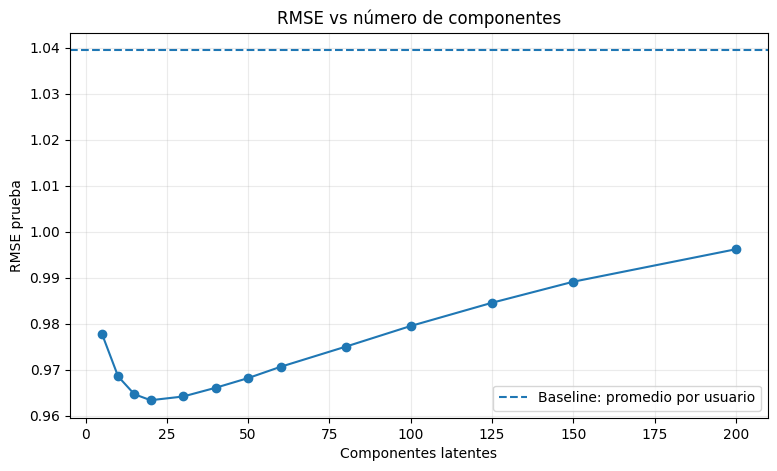

In [6]:
# Crear un arreglo con las posiciones de todas las evaluaciones en el df ratings.
indices = np.arange(len(ratings))
# 4a. Dividir las evaluaciones en 80% entrenamiento y 20% de prueba
# Utilizamos random state constante para mantener la reproducibilidad de los datos
idx_train,idx_test = train_test_split(indices,test_size=.20,random_state=RANDOM_STATE)
# Separar el conjunto de datos correspondiente al conjunto de entrenamiento
Mtr,Utr,Ytr = M[idx_train],U[idx_train],Y[idx_train]
# Separar el conjunto de datos correspondiente al conjunto de prueba
Mte,Ute,Yte = M[idx_test],U[idx_test],Y[idx_test]
# Contar cuantas evaluaciones realizo cada usuario en el conjunto de entrenamiento
cuenta_train = np.bincount(Utr,minlength=n_users)
# Realizar una suma de las calificaciones que cada usuario otorgo en el conjunto de entrenamiento
suma_train = np.bincount(Utr,weights=Ytr,minlength=n_users)
# Calcular la media utilizado la suma y el conteo total calculado anteriormente
medias_train = np.divide(suma_train,cuenta_train,
                         out=np.full(n_users,Ytr.mean()),where=cuenta_train>0)
# Crear la matriz dispersa que utilizaremos para entrenar el modelo SVD
X_train = sparse.csr_matrix((Ytr-medias_train[Utr],(Mtr,Utr)),shape=(n_movies,n_users))

# Definir una lista posible de numeros de componentes latentes
k_candidatos = [5,10,15,20,30,40,50,60,80,100,125,150,200]
# Un solo ajuste con k máximo; evaluamos reconstrucciones parciales con sus primeros k.
# 4b. Entrenar el modelo SVD y reportar el RMSE con el conjunto de prueba.
svd_max = TruncatedSVD(n_components=max(k_candidatos),n_iter=5,random_state=RANDOM_STATE)
# Entrenar el modelo SVD con la matriz Xtrain y transformar las peliculas a una
# representacion de 200 componentes.
Z_max = svd_max.fit_transform(X_train)
# Obtener la representacion de los usuarios en el espacio latente.
V_max = svd_max.components_.T
# Cada test pair tiene un producto escalar entre sus vectores latentes.
componentes_test = Z_max[Mte].astype(np.float64)*V_max[Ute].astype(np.float64)
# Calcular la suma acumulada de las contribuciones de los componentes latentes.
pred_acumulada = np.cumsum(componentes_test,axis=1)
# 4c. Obtener la gráfica RMSE contra número de componentes latentes.
rmse = {}
for k in k_candidatos:
    pred = np.clip(medias_train[Ute]+pred_acumulada[:,k-1],1,5)
    rmse[k]=float(np.sqrt(np.mean((pred-Yte)**2)))
k_optimo = min(rmse,key=rmse.get)
rmse_baseline = float(np.sqrt(np.mean((medias_train[Ute]-Yte)**2)))
print('Partición:',len(idx_train),'train;',len(idx_test),'test')
print('Baseline RMSE:',round(rmse_baseline,4))
print('Mejor k:',k_optimo,'RMSE:',round(rmse[k_optimo],4))
display(pd.DataFrame({'k':list(rmse.keys()),'RMSE_prueba':list(rmse.values())}))
plt.figure(figsize=(9,5));plt.plot(list(rmse),list(rmse.values()),'o-')
plt.axhline(rmse_baseline,ls='--',label='Baseline: promedio por usuario')
plt.xlabel('Componentes latentes');plt.ylabel('RMSE prueba');plt.title('RMSE vs número de componentes')
plt.grid(alpha=.25);plt.legend();plt.show()

Se dividen las evaluaciones, no las matrices, en 80% entrenamiento y 20% prueba, con semilla 42. El promedio por usuario se calcula exclusivamente en entrenamiento para no filtrar información de la prueba. Se reconstruyen únicamente las parejas usuario–película que están en el conjunto de prueba, evitando una matriz densa reconstruida. El mejor `k` en la búsqueda fue 20, con RMSE ≈0.9633; baseline promedio por usuario ≈1.0394.

### 4d. Selecciona el número de componentes que consideres más adecuado. Justifica la selección de dicho valor.
El número de componentes que obtuvo el menor RMSE fue de 20 componentes, con un RMSE de 0.9633. Esto significa que la magnitud cuadrática media del error equivale aproximadamente a 0.96 estrellas.

Dentro de los valores evaluados, 20 componentes ofrecen el mejor equilibrio entre la capacidad del modelo para representar patrones y su capacidad para predecir calificaciones desconocidas. Es posible que, al aumentar los componentes, el modelo empiece a incorporar patrones poco generalizables o ruido de los datos de entrenamiento. No podemos demostrar sobreajuste únicamente con esta tabla, pero el comportamiento es compatible con esa posibilidad.

# **Ejercicio - 5: comparación varianza explicada vs RMSE**
El criterio de varianza busca reconstruir estructura; el de RMSE busca predecir ratings no vistos. Con datos muy dispersos, cientos de componentes pueden explicar mucho ruido y sobreajustar. Se elige `k=20` por el mínimo exploratorio de RMSE entre candidatos, aunque retiene solo ≈16.87% de varianza de la matriz completa de residuos. Como el objetivo es construir un sistema de recomendación que prediga preferencias, damos prioridad al RMSE.

In [7]:
print('Selección final:', k_optimo)
print('Varianza descriptiva retenida por ese k: %.2f%%' % (100*varianza_acum[k_optimo-1]))
print('RMSE mínimo explorado: %.4f' % rmse[k_optimo])

Selección final: 20
Varianza descriptiva retenida por ese k: 16.87%
RMSE mínimo explorado: 0.9633


# **Ejercicio - 6: sistema de recomendación colaborativo**

In [8]:
# Crear el modelo SVD definitivo con 20 como numero de componentes optimo
svd_final = TruncatedSVD(n_components=k_optimo,n_iter=7,random_state=RANDOM_STATE)
# Entrenar SVD y obtener los factores latentes
Z = svd_final.fit_transform(X)
# Convertir los factores latentes a un tipo de dato numerico y despues normalizar
# cada vector. La matriz ahora sera la base del sistema de recomendaciones.
F_svd = normalize(Z.astype(np.float32))
# 6a. Calcular la similitud entre cada pelicula y todas las demas peliculas.
similitud_svd = cosine_similarity(F_svd)
# Identificar que peliculas tienen al menos una calificacion almacenada en la
# matriz de entrenamiento.
con_ratings = matriz_utilidad.getnnz(axis=1) > 0
# 6b. Mostrar las dimensiones de la matriz de similitud
print('Matriz de similitud SVD:',similitud_svd.shape)

# Construir una funcion que permita recomendar peliculas a partir de una o
# varias favoritas.
def recomendar(favoritas, factores, n=10):
    # media de cosenos de cada candidato con las peliculas favoritas o una sola semilla
    # Convertir los nombres de las peliculas favoritas en las posiciones que
    # ocupan dentro de la matriz de factores latentes.
    filas = np.array([int(movies.index[movies.title.eq(t)][0]) for t in favoritas])
    # Calcular que tan similar es cada pelicula del catalogo respecto a la lista
    # de peliculas favoritas.
    puntajes = factores[:, filas].mean(axis=1)
    # Asignar un puntaje extremadamente bajo a las peliculas que no tienen
    # evaluaciones de entrenamiento, ya que no tienen informacion colaborativa
    # de entrenamiento.
    puntajes[~con_ratings] = -np.inf
    # Excluir las peliculas favoritas, para que el sistema no las recomiende
    # en el resultado
    puntajes[filas] = -np.inf
    # Ordenas las peliculas segun sus puntajes y selecciona las n mejores.
    orden = np.argsort(-puntajes)[:n]
    # Construir la tabla de recomendaciones
    return pd.DataFrame({'movie_id':movies.movie_id.iloc[orden].to_numpy(),
                         'pelicula':movies.title.iloc[orden].to_numpy(),
                         'generos':movies.genres.iloc[orden].to_numpy(),
                         'similitud':puntajes[orden]})

# 6c. Elegir una pelicula y obtener 10 recomendaciones
pelicula_semilla = 'Men in Black (1997)'
recom_svd_mib = recomendar([pelicula_semilla],similitud_svd,10)
display(recom_svd_mib)

Matriz de similitud SVD: (3883, 3883)


,movie_id,pelicula,generos,similitud
0,3624,Shanghai Noon (2000),Action,0.772051
1,380,True Lies (1994),Action|Adventure|Comedy|Romance,0.767920
2,2273,Rush Hour (1998),Action|Thriller,0.725728
3,1356,Star Trek: First Contact (1996),Action|Adventure|Sci-Fi,0.718071
4,2353,Enemy of the State (1998),Action|Thriller,0.716892
5,1527,"Fifth Element, The (1997)",Action|Sci-Fi,0.700917
6,3175,Galaxy Quest (1999),Adventure|Comedy|Sci-Fi,0.700599
7,780,Independence Day (ID4) (1996),Action|Sci-Fi|War,0.681540
8,2617,"Mummy, The (1999)",Action|Adventure|Horror|Thriller,0.664336
9,3793,X-Men (2000),Action|Sci-Fi,0.654302


Se ajusta de nuevo el SVD truncado con `k=20` sobre el 80% de entrenamiento y se calcula el coseno entre vectores latentes de todas las películas. Matriz de similitud: **3,883 × 3,883**, con diagonal cercana a 1 para filmes con vector no nulo; los 177 sin ratings se excluyen de la recuperación. Ejemplo elegido: *Men in Black (1997)*. La similitud no es una probabilidad de agrado ni una calificación estimada.

### 6d. ¿Las recomendaciones mostradas son coherentes o esperadas? Comenta al respecto.
Los resultados muestran que Shanghai Noon presenta la mayor similitud con Men in Black, seguida de peliculas como True Lies, Rush Hour y Star Trek. Estas relaciones se obtuvieron a partir de los patrones de calificaciones de los usuarios, no mediante una comparación directa de los géneros cinematográficos. Considero que son coherentes ya que son peliculas similares en cuestion de generos y popularidad.

### 6e. ¿Cómo explicarías a alguien no experto en la parte técnica la manera en que este método SVD está generando las recomendaciones?
El sistema de recomendación SVD funciona identificando patrones en las calificaciones que miles de usuarios han dado a diferentes películas. A partir de esta información, crea una especie de “huella digital” para cada película, formada por 20 valores que resumen cómo se relaciona con los gustos de los usuarios. Después, compara estas huellas para encontrar películas que suelen agradar a personas con preferencias similares. De esta manera, puede recomendar títulos que probablemente sean de nuestro interés, incluso si pertenecen a géneros diferentes, ya que se basa en los gustos compartidos de los usuarios y no únicamente en el tipo de película.

# **Ejercicio - 7: sistema de recomendación híbrido**

In [9]:
# Extraer el año de estreno que aparece al final del titulo de cada pelicula
# y almacenarlos en una nueva columna llamada 'year'
movies['year']=pd.to_numeric(movies.title.str.extract(r'\((\d{4})\)$')[0])
# 7a. Convertir el año de estreno de cada pelicula la decada correspondiente.
movies['decade']=(movies.year//10*10).astype('Int64')
# Convertir la decada de cada pelicula en una representacion numerica que el
# modelo pueda utilizar con OneHotEncoding
B_dec = pd.get_dummies(movies.decade,prefix='decada',dtype=float).to_numpy()
# Identificar los generos existentes en los datos con comprension de conjuntos
lista_generos = sorted({g for gr in movies.genres for g in gr.split('|')})
# Construir una matriz que indica a qué géneros pertenece cada película.
B_gen = np.asarray([[float(g in gr.split('|')) for g in lista_generos]
                     for gr in movies.genres],dtype=np.float32)
# Crear una tabla que combine evaluaciones e informacion demografica de los
# usuarios que realizarion estas evaluaciones.
joined=pd.DataFrame({'fila_pelicula':M,'fila_usuario':U,'rating':Y}).merge(
    users.assign(fila_usuario=users.user_id.map(user_to_col)),on='fila_usuario',how='left')
# Contar cuantas evaluaciones tiene cada pelicula en el conjunto de entrenamiento
conteo_pelicula=np.bincount(M,minlength=n_movies)
# Calcular el promedio de calificaciones de cada pelicula con el conjunto de
# entrenamiento
promedio_pelicula=np.divide(np.bincount(M,weights=Y,minlength=n_movies),
                           conteo_pelicula,out=np.full(n_movies,Y.mean()),
                           where=conteo_pelicula>0)
# Definir una funcion que construira un perfil de preferencias demograficas
# para cada pelicula
# En la variable columna definimos que caracteristica demografica queremos analizar
def perfil_demografico(columna,clases,shrink=10):
    indices_col = joined[columna].map({v:i for i,v in enumerate(clases)}).to_numpy()
    indices_fila = joined.fila_pelicula.to_numpy()
    n_clases=len(clases)
    sumas=sparse.coo_matrix((joined.rating.to_numpy(),(indices_fila,indices_col)),
                           shape=(n_movies,n_clases)).toarray()
    cuentas=sparse.coo_matrix((np.ones(len(joined)),(indices_fila,indices_col)),
                             shape=(n_movies,n_clases)).toarray()
    # Preferencia del grupo respecto al promedio general de esa película.
    diferencia = (sumas + shrink*promedio_pelicula[:,None])/(cuentas+shrink)-promedio_pelicula[:,None]
    # Factor de confianza para cada pelicula segun la cantidad de evaluaciones
    confianza = np.minimum(1,conteo_pelicula[:,None]/50)
    # Devuelve la matriz de perfiles demograficos normalizada y ajustada segun
    # la confianza de cada pelicula
    return normalize(diferencia)*confianza

# 7b. Factores adicionales de los usuarios: edad y ocupacion
# Ejecutar la funcion con la edad como caracteristica
B_age=perfil_demografico('age',sorted(users.age.unique()))
# Ejecutar la funcion con la ocupacion como caracteristica
B_occ=perfil_demografico('occupation',sorted(users.occupation.unique()))
# Crear un diccionario que asigna una importancia relativa a cada bloque de
# informacion
pesos={'SVD':.62,'generos':.20,'decada':.08,'edad':.06,'ocupacion':.04}
# Combinar los 5 bloques de informacion en una sola matriz, aplicando los pesos
# correspondientes y normalizando el resultado
F_hibrido=normalize(np.hstack([
    F_svd*np.sqrt(pesos['SVD']),normalize(B_gen)*np.sqrt(pesos['generos']),
    normalize(B_dec)*np.sqrt(pesos['decada']),B_age*np.sqrt(pesos['edad']),
    B_occ*np.sqrt(pesos['ocupacion'])
]).astype(np.float32))
similitud_hibrida = cosine_similarity(F_hibrido)
# 7c. Dimensiones de la matriz hibrida integrando SVD, generos, decada, edad y
# ocupacion
print('Dimensión matriz híbrida:',F_hibrido.shape)
# Desglose de cuantas columnas aporta cada bloque de informacion
print('Desglose:',k_optimo,B_dec.shape[1],B_gen.shape[1],B_age.shape[1],B_occ.shape[1])
# Utiliza la función recomendar con los factores híbridos
recom_hibrido_mib=recomendar([pelicula_semilla],similitud_hibrida,10)
# 7e. Crear un df para comparar las recomendaciones obtenidas con los dos modelos
comparativa_mib=pd.DataFrame({
    'SVD':recom_svd_mib.pelicula,'Similitud SVD':recom_svd_mib.similitud,
    'Genero SVD':recom_svd_mib.generos,
    'Híbrido':recom_hibrido_mib.pelicula,'Similitud híbrida':recom_hibrido_mib.similitud,
    'Genero Hibrido':recom_hibrido_mib.generos})
display(comparativa_mib)

Dimensión matriz híbrida: (3883, 76)
Desglose: 20 10 18 7 21


,SVD,Similitud SVD,Genero SVD,Híbrido,Similitud híbrida,Genero Hibrido
0,Shanghai Noon (2000),0.772051,Action,True Lies (1994),0.761269,Action|Adventure|Comedy|Romance
1,True Lies (1994),0.767920,Action|Adventure|Comedy|Romance,Star Trek: First Contact (1996),0.745898,Action|Adventure|Sci-Fi
2,Rush Hour (1998),0.725728,Action|Thriller,Galaxy Quest (1999),0.740511,Adventure|Comedy|Sci-Fi
3,Star Trek: First Contact (1996),0.718071,Action|Adventure|Sci-Fi,Jurassic Park (1993),0.687914,Action|Adventure|Sci-Fi
4,Enemy of the State (1998),0.716892,Action|Thriller,Total Recall (1990),0.673059,Action|Adventure|Sci-Fi|Thriller
5,"Fifth Element, The (1997)",0.700917,Action|Sci-Fi,Independence Day (ID4) (1996),0.667419,Action|Sci-Fi|War
6,Galaxy Quest (1999),0.700599,Adventure|Comedy|Sci-Fi,"Fifth Element, The (1997)",0.663773,Action|Sci-Fi
7,Independence Day (ID4) (1996),0.681540,Action|Sci-Fi|War,Enemy of the State (1998),0.657265,Action|Thriller
8,"Mummy, The (1999)",0.664336,Action|Adventure|Horror|Thriller,Stargate (1994),0.650218,Action|Adventure|Sci-Fi
9,X-Men (2000),0.654302,Action|Sci-Fi,Star Trek IV: The Voyage Home (1986),0.640060,Action|Adventure|Sci-Fi


Agregamos cuatro bloques de información a los **20** factores latentes: **década** (10 columnas one-hot), **géneros** (18 categorías multietiqueta), **edad** (7 grupos) y **ocupación** (21 grupos). Los últimos dos se convierten en perfiles **agregados por película** de diferencias de promedios con suavizado bayesiano (`shrink=10`), calculados solo con ratings de entrenamiento. Nunca se agrega la edad u ocupación de un usuario particular como si fueran propiedades de una película. Dimensión final **3,883 × 76**. Se normalizan bloques y se aplican pesos SVD=.62, géneros=.20, década=.08, edad=.06 y ocupación=.04, para que las 21 ocupaciones no dominen por su número.

### 7d. En general, ¿qué beneficios podría aportar esta nueva matriz aumentada, en relación con la basada solamente en SVD?
La principal ventaja de la matriz híbrida es que permite generar recomendaciones más completas y personalizadas, ya que no se basa únicamente en los patrones de calificaciones de los usuarios, como ocurre con SVD, sino que también considera información adicional, como los géneros, las décadas de estreno y las preferencias de distintos grupos de edad y ocupación. Esto ayuda a identificar relaciones entre películas que podrían pasar desapercibidas utilizando solamente SVD, además de facilitar la explicación de por qué se recomienda una película. En general, combinar estas características puede mejorar la variedad y relevancia de las recomendaciones, aunque sería necesario evaluar ambos modelos para comprobar si realmente existe una mejora en su desempeño.

### 7f. Comentarios sobre resultados
El modelo híbrido permite obtener recomendaciones más relacionadas con las características de la película seleccionada, en este caso Men in Black, ya que considera tanto las preferencias de otros usuarios como los géneros y la época de estreno. Esto ayuda a recomendar películas de ciencia ficción, aventura y comedia de los años noventa, que comparten características con la película original. A diferencia del modelo basado únicamente en SVD, el híbrido puede ofrecer recomendaciones más fáciles de explicar y evitar algunas sugerencias que parecen poco relacionadas. Sin embargo, la importancia asignada a cada característica se estableció de manera manual, por lo que sería necesario realizar más pruebas para comprobar si realmente mejora los resultados. Además, al utilizar información demográfica de los usuarios, es importante considerar aspectos de privacidad y evitar posibles sesgos.

# **Ejercicio - 8: sistema de recomendación mediante un agente inteligente**

In [10]:
perfiles = {
    'Romance / drama':['Titanic (1997)','Pretty Woman (1990)','Notting Hill (1999)',
                       'Sleepless in Seattle (1993)','When Harry Met Sally... (1989)'],
    'Animacion familiar':['Toy Story (1995)','Toy Story 2 (1999)','Aladdin (1992)',
                          'Beauty and the Beast (1991)','Lion King, The (1994)'],
    'Ciencia ficcion / accion':['Matrix, The (1999)',
                               'Star Wars: Episode IV - A New Hope (1977)',
                               'Terminator 2: Judgment Day (1991)',
                               'Blade Runner (1982)','Alien (1979)']
}

def candidatos_para_agente(favoritas):
    svd10=recomendar(favoritas,similitud_svd,10)
    hib10=recomendar(favoritas,similitud_hibrida,10)
    comparacion=pd.DataFrame({'Película SVD':svd10.pelicula,'Similitud SVD':svd10.similitud,
                               'Película híbrido':hib10.pelicula,'Similitud híbrido':hib10.similitud})
    # Pertenencia por ID para validar salida del agente
    candidatos=pd.concat([svd10,hib10]).drop_duplicates('movie_id').reset_index(drop=True)
    return comparacion,candidatos

# 8a. Tabla comparativa de SVD y modelo hibrido
comparacion,candidatos=candidatos_para_agente(perfiles['Romance / drama'])
display(comparacion)

,Película SVD,Similitud SVD,Película híbrido,Similitud híbrido
0,"League of Their Own, A (1992)",0.773166,"American President, The (1995)",0.738629
1,"American President, The (1995)",0.759650,Ghost (1990),0.691721
2,Erin Brockovich (2000),0.706003,"League of Their Own, A (1992)",0.690460
3,Ghost (1990),0.700693,Dave (1993),0.688834
4,Jerry Maguire (1996),0.676953,Ever After: A Cinderella Story (1998),0.622188
5,Ever After: A Cinderella Story (1998),0.666229,My Cousin Vinny (1992),0.620037
6,Top Gun (1986),0.662208,While You Were Sleeping (1995),0.616510
7,Steel Magnolias (1989),0.646878,Forrest Gump (1994),0.608734
8,Dave (1993),0.637560,My Best Friend's Wedding (1997),0.604802
9,My Cousin Vinny (1992),0.630554,You've Got Mail (1998),0.601001


# MovieLens Recommendation Agent

Eres un agente recomendador de películas riguroso.

## Objetivo
Seleccionar exactamente 5 películas distintas y justificar cada decisión.

## Restricciones
- Solo puedes recomendar películas de la lista de candidatos proporcionada.
- No puedes recomendar ninguna de las cinco películas favoritas originales.
- Utiliza exclusivamente los metadatos proporcionados: títulos, géneros, años y puntuaciones.
- Las puntuaciones representan similitudes del coseno, no probabilidades ni ratings.
- No inventes tramas, repartos, directores, años ni información no incluida.
- Equilibra afinidad y diversidad, considerando el consenso entre SVD e híbrido.
- No infieras datos sensibles sobre la persona.
- No utilices fuentes externas.

## Procedimiento
1. Recibir las cinco películas favoritas y las listas de candidatos SVD e híbrido.
2. Excluir las cinco favoritas originales.
3. Eliminar candidatos duplicados.
4. Comparar similitudes, géneros y consenso entre los modelos.
5. Seleccionar exactamente cinco películas distintas.
6. Generar una justificación verificable para cada película.
7. Validar que todos los IDs estén incluidos en los candidatos.

Si no hay suficientes datos o al menos cinco candidatos válidos, solicita la información faltante. Nunca inventes películas para completar el resultado.

## Formato obligatorio
Devuelve exclusivamente JSON válido con esta estructura:

```json
{
  "recomendaciones": [
    {
      "movie_id": 123,
      "justificacion": "Texto respaldado por datos"
    }
  ]
}
```

Cuando existan suficientes candidatos válidos, el resultado debe contener exactamente cinco objetos, con IDs únicos y justificaciones basadas únicamente en los datos proporcionados.

In [11]:
# Funcion para recomendar peliculas
def validar_recomendaciones(respuesta, favoritas, candidatos):

    # Obtener las recomendaciones del agente
    items = respuesta['recomendaciones']

    # Identificar las películas que pueden recomendarse
    permitidos = set(candidatos.movie_id.astype(int))

    # Identificar las cinco películas favoritas originales
    prohibidos = set(
        movies[movies.title.isin(favoritas)].movie_id.astype(int)
    )

    # Obtener los IDs recomendados
    ids = [int(x['movie_id']) for x in items]

    # Verificar que sean exactamente cinco películas distintas
    assert len(ids) == 5 and len(set(ids)) == 5, \
        'Se necesitan cinco IDs únicos'

    # Verificar que pertenezcan a la lista de candidatos
    assert set(ids) <= permitidos, \
        'Se detectaron películas fuera de los candidatos'

    # Verificar que no se recomienden las favoritas originales
    assert not set(ids) & prohibidos, \
        'No se deben devolver películas favoritas'

    # Verificar que todas tengan justificación
    assert all(
        isinstance(x['justificacion'], str)
        and x['justificacion'].strip()
        for x in items
    ), 'Falta una justificación'

    return True

## Resultados entregados por el agente

In [12]:

{
  "recomendaciones": [
    {
      "movie_id": 11,
      "justificacion": "The American President (1995) combina comedia, drama y romance, géneros afines a las cinco películas favoritas. Presenta una similitud del coseno de 0.740437 en el modelo híbrido y aparece en ambos métodos de recomendación. Se selecciona por su alta afinidad y el consenso entre SVD e híbrido."
    },
    {
      "movie_id": 587,
      "justificacion": "Ghost (1990) combina comedia, romance y thriller. Comparte géneros con las películas favoritas e introduce el thriller como elemento de diversidad. Su presencia entre los candidatos y su similitud híbrida de 0.705327 respaldan su selección."
    },
    {
      "movie_id": 1393,
      "justificacion": "Jerry Maguire (1996) pertenece a los géneros drama y romance, directamente relacionados con las preferencias originales. Aparece entre las recomendaciones de SVD y del modelo híbrido, alcanzando una similitud híbrida de 0.647058. Su selección refuerza la afinidad temática."
    },
    {
      "movie_id": 3512,
      "justificacion": "Return to Me (2000) combina drama y romance, dos géneros predominantes entre las películas favoritas. Aparece en las listas de ambos modelos, con una similitud híbrida de 0.609895. Se recomienda por su correspondencia temática y el consenso entre métodos."
    },
    {
      "movie_id": 2396,
      "justificacion": "Shakespeare in Love (1998) combina comedia y romance, características presentes en las preferencias originales. Forma parte de los candidatos generados por los modelos y permite incorporar variedad de títulos y años sin alejarse de los géneros preferidos."
    }
  ]
}


{'recomendaciones': [{'movie_id': 11,
   'justificacion': 'The American President (1995) combina comedia, drama y romance, géneros afines a las cinco películas favoritas. Presenta una similitud del coseno de 0.740437 en el modelo híbrido y aparece en ambos métodos de recomendación. Se selecciona por su alta afinidad y el consenso entre SVD e híbrido.'},
  {'movie_id': 587,
   'justificacion': 'Ghost (1990) combina comedia, romance y thriller. Comparte géneros con las películas favoritas e introduce el thriller como elemento de diversidad. Su presencia entre los candidatos y su similitud híbrida de 0.705327 respaldan su selección.'},
  {'movie_id': 1393,
   'justificacion': 'Jerry Maguire (1996) pertenece a los géneros drama y romance, directamente relacionados con las preferencias originales. Aparece entre las recomendaciones de SVD y del modelo híbrido, alcanzando una similitud híbrida de 0.647058. Su selección refuerza la afinidad temática.'},
  {'movie_id': 3512,
   'justificacion':

In [13]:
import json

for nombre, favs in perfiles.items():

    svd10 = recomendar(favs, similitud_svd, 10)
    hib10 = recomendar(favs, similitud_hibrida, 10)

    datos_agente = {
        "perfil": nombre,
        "favoritas": favs,
        "recomendaciones_svd": svd10.to_dict("records"),
        "recomendaciones_hibridas": hib10.to_dict("records")
    }

    print(f"\n{'='*60}")
    print(f"PERFIL: {nombre}")
    print(json.dumps(datos_agente, ensure_ascii=False, indent=2))


PERFIL: Romance / drama
{
  "perfil": "Romance / drama",
  "favoritas": [
    "Titanic (1997)",
    "Pretty Woman (1990)",
    "Notting Hill (1999)",
    "Sleepless in Seattle (1993)",
    "When Harry Met Sally... (1989)"
  ],
  "recomendaciones_svd": [
    {
      "movie_id": 3255,
      "pelicula": "League of Their Own, A (1992)",
      "generos": "Comedy|Drama",
      "similitud": 0.7731661796569824
    },
    {
      "movie_id": 11,
      "pelicula": "American President, The (1995)",
      "generos": "Comedy|Drama|Romance",
      "similitud": 0.7596498727798462
    },
    {
      "movie_id": 3408,
      "pelicula": "Erin Brockovich (2000)",
      "generos": "Drama",
      "similitud": 0.7060034871101379
    },
    {
      "movie_id": 587,
      "pelicula": "Ghost (1990)",
      "generos": "Comedy|Romance|Thriller",
      "similitud": 0.7006931304931641
    },
    {
      "movie_id": 1393,
      "pelicula": "Jerry Maguire (1996)",
      "generos": "Drama|Romance",
      "similitud"

# **Ejercicio - 9: Evaluación del agente**
### 9a. Resumen de resultados
Para evaluar el agente recomendador se utilizaron tres perfiles con preferencias diferentes: romance y drama, animación familiar, y ciencia ficción y acción. Para cada perfil se generaron diez recomendaciones mediante SVD y diez mediante el modelo híbrido, utilizando el conjunto completo de datos. Posteriormente, se utilizó ChatGPT para seleccionar cinco películas de las listas obtenidas, considerando la similitud con las favoritas, la coincidencia entre ambos modelos y la variedad de géneros. Los resultados muestran recomendaciones relacionadas con las preferencias originales, pero también incluyen películas con características diferentes para ofrecer mayor diversidad. Finalmente, se validó que las películas seleccionadas pertenecieran a las listas de candidatos, que no se repitieran y que ninguna correspondiera a las favoritas originales.

In [14]:
# Pregunta 9: Recomendaciones del agente GPT-6
# Basadas en los nuevos candidatos SVD e híbridos

ejemplos_gpt6 = {

    'Romance / drama': [
        (
            'American President, The (1995)',
            'Combina comedia, drama y romance, géneros afines a las '
            'películas favoritas. Aparece en ambos modelos y presenta '
            'alta similitud del coseno.'
        ),
        (
            'Ghost (1990)',
            'Combina comedia y romance con thriller, ofreciendo '
            'diversidad temática. Aparece entre las recomendaciones '
            'de SVD y del modelo híbrido.'
        ),
        (
            'League of Their Own, A (1992)',
            'Comparte comedia y drama con el perfil original. '
            'Presenta una similitud de 0.7732 en SVD y 0.6905 '
            'en el modelo híbrido.'
        ),
        (
            'Jerry Maguire (1996)',
            'Combina drama y romance, dos géneros relacionados '
            'con las preferencias originales. Presenta una '
            'similitud SVD de 0.6770.'
        ),
        (
            'Ever After: A Cinderella Story (1998)',
            'Comparte drama y romance con las películas favoritas. '
            'Aparece en ambos modelos, con similitudes de '
            '0.6662 en SVD y 0.6222 en el híbrido.'
        )
    ],

    'Animacion familiar': [
        (
            "Bug's Life, A (1998)",
            'Combina animación, contenido infantil y comedia. '
            'Es la película con mayor similitud del coseno '
            'en ambos modelos para este perfil.'
        ),
        (
            'Mulan (1998)',
            'Comparte animación y contenido infantil con '
            'las favoritas. Presenta similitudes de 0.8126 '
            'en SVD y 0.8002 en el híbrido.'
        ),
        (
            'Tarzan (1999)',
            'Pertenece a los géneros animación e infantil. '
            'Aparece en ambos modelos y mantiene la afinidad '
            'con las preferencias originales.'
        ),
        (
            'Little Mermaid, The (1989)',
            'Combina animación, contenido infantil, comedia, '
            'musical y romance. Aporta diversidad de géneros '
            'y aparece en ambos modelos.'
        ),
        (
            'Fantasia 2000 (1999)',
            'Combina animación, contenido infantil y musical. '
            'Aparece en ambas listas y ofrece variedad '
            'dentro de la temática familiar.'
        )
    ],

    'Ciencia ficcion / accion': [
        (
            'Terminator, The (1984)',
            'Combina acción, ciencia ficción y thriller. '
            'Presenta la mayor similitud del coseno '
            'en ambos modelos para este perfil.'
        ),
        (
            'Aliens (1986)',
            'Comparte acción, ciencia ficción y thriller '
            'con el perfil original, incorporando también '
            'el género bélico. Aparece en ambos modelos.'
        ),
        (
            'Star Wars: Episode V - The Empire Strikes Back (1980)',
            'Combina acción, aventura, drama, ciencia ficción '
            'y guerra. Aparece en ambos modelos y aporta '
            'diversidad de géneros.'
        ),
        (
            'Raiders of the Lost Ark (1981)',
            'Combina acción y aventura, manteniendo afinidad '
            'con las preferencias originales y ofreciendo '
            'variedad frente a la ciencia ficción.'
        ),
        (
            'Star Trek: The Wrath of Khan (1982)',
            'Combina acción, aventura y ciencia ficción. '
            'Aparece entre los candidatos del modelo híbrido '
            'con una similitud de 0.5331.'
        )
    ]
}


In [15]:
for nombre,favs in perfiles.items():
    tabla,cands = candidatos_para_agente(favs)
    print('PERFIL:',nombre,'| 10 SVD + 10 híbridas')
    display(tabla)
    seleccion=[]
    for titulo,justificacion in ejemplos_gpt6[nombre]:
        movie_id = int(movies.loc[movies.title.eq(titulo),'movie_id'].iloc[0])
        seleccion.append({'movie_id':movie_id,'justificacion':justificacion})
    salida={'recomendaciones':seleccion}
    validar_recomendaciones(salida,favs,cands)
    print('Cinco propuestas verificadas:')
    display(pd.DataFrame([{'pelicula':movies.loc[movies.movie_id.eq(x['movie_id']),'title'].iloc[0],
                           'justificacion':x['justificacion']} for x in seleccion]))
    print('Validación de títulos permitidos: correcta')

PERFIL: Romance / drama | 10 SVD + 10 híbridas


,Película SVD,Similitud SVD,Película híbrido,Similitud híbrido
0,"League of Their Own, A (1992)",0.773166,"American President, The (1995)",0.738629
1,"American President, The (1995)",0.759650,Ghost (1990),0.691721
2,Erin Brockovich (2000),0.706003,"League of Their Own, A (1992)",0.690460
3,Ghost (1990),0.700693,Dave (1993),0.688834
4,Jerry Maguire (1996),0.676953,Ever After: A Cinderella Story (1998),0.622188
5,Ever After: A Cinderella Story (1998),0.666229,My Cousin Vinny (1992),0.620037
6,Top Gun (1986),0.662208,While You Were Sleeping (1995),0.616510
7,Steel Magnolias (1989),0.646878,Forrest Gump (1994),0.608734
8,Dave (1993),0.637560,My Best Friend's Wedding (1997),0.604802
9,My Cousin Vinny (1992),0.630554,You've Got Mail (1998),0.601001


Cinco propuestas verificadas:


,pelicula,justificacion
0,"American President, The (1995)","Combina comedia, drama y romance, géneros afin..."
1,Ghost (1990),"Combina comedia y romance con thriller, ofreci..."
2,"League of Their Own, A (1992)",Comparte comedia y drama con el perfil origina...
3,Jerry Maguire (1996),"Combina drama y romance, dos géneros relaciona..."
4,Ever After: A Cinderella Story (1998),Comparte drama y romance con las películas fav...


Validación de títulos permitidos: correcta
PERFIL: Animacion familiar | 10 SVD + 10 híbridas


,Película SVD,Similitud SVD,Película híbrido,Similitud híbrido
0,"Bug's Life, A (1998)",0.857578,"Bug's Life, A (1998)",0.811342
1,Mulan (1998),0.812585,Mulan (1998),0.800172
2,"Little Mermaid, The (1989)",0.809249,Tarzan (1999),0.738696
3,Lady and the Tramp (1955),0.763455,Fantasia 2000 (1999),0.720405
4,Fantasia 2000 (1999),0.761863,"Little Mermaid, The (1989)",0.716406
5,Tarzan (1999),0.756743,"Jungle Book, The (1967)",0.690283
6,Mary Poppins (1964),0.747571,"Iron Giant, The (1999)",0.681799
7,"Jungle Book, The (1967)",0.730923,Babe (1995),0.655727
8,Cinderella (1950),0.729728,Lady and the Tramp (1955),0.651802
9,Winnie the Pooh and the Blustery Day (1968),0.713730,Mary Poppins (1964),0.642161


... (3 outputs left out)

,Película SVD,Similitud SVD,Película híbrido,Similitud híbrido
0,"Terminator, The (1984)",0.790091,"Terminator, The (1984)",0.699246
1,Aliens (1986),0.788976,Aliens (1986),0.693222
2,Raiders of the Lost Ark (1981),0.708168,Star Wars: Episode V - The Empire Strikes Back...,0.589035
3,Star Wars: Episode V - The Empire Strikes Back...,0.691758,Raiders of the Lost Ark (1981),0.575474
4,Close Encounters of the Third Kind (1977),0.647331,Star Trek: The Wrath of Khan (1982),0.533134
5,Die Hard (1988),0.622136,Nikita (La Femme Nikita) (1990),0.529005
6,Nikita (La Femme Nikita) (1990),0.611065,Die Hard (1988),0.523124
7,"Professional, The (a.k.a. Leon: The Profession...",0.606604,Close Encounters of the Third Kind (1977),0.515580
8,"Sixth Sense, The (1999)",0.591543,Twelve Monkeys (1995),0.502650
9,Indiana Jones and the Last Crusade (1989),0.590630,"Fugitive, The (1993)",0.498681


Cinco propuestas verificadas:


,pelicula,justificacion
0,"Terminator, The (1984)","Combina acción, ciencia ficción y thriller. Pr..."
1,Aliens (1986),"Comparte acción, ciencia ficción y thriller co..."
2,Star Wars: Episode V - The Empire Strikes Back...,"Combina acción, aventura, drama, ciencia ficci..."
3,Raiders of the Lost Ark (1981),"Combina acción y aventura, manteniendo afinida..."
4,Star Trek: The Wrath of Khan (1982),"Combina acción, aventura y ciencia ficción. Ap..."


Validación de títulos permitidos: correcta


### 9b. ¿Qué recomendaciones fueron coherentes? ¿Detectaste alucinaciones?
La mayoría de las recomendaciones fueron coherentes con las preferencias de cada perfil. Por ejemplo, *The American President* comparte comedia, drama y romance con las películas favoritas del primer grupo; *A Bug's Life* y *Mulan* mantienen los géneros de animación e infantil del segundo; mientras que *The Terminator* y *Aliens* coinciden en acción y ciencia ficción con el tercero. También se incluyeron películas de géneros complementarios para ofrecer mayor variedad. No se identificaron alucinaciones evidentes, ya que las películas recomendadas pertenecen a los candidatos originales y sus justificaciones se basaron en los géneros, años y similitudes proporcionados. Sin embargo, la validación automática únicamente comprueba que las películas sean válidas, por lo que las explicaciones también deben revisarse para confirmar que no contengan información incorrecta.

### 9c. Incluye tus comentarios sobre los resultados obtenidos por el agente
Considero que los resultados del agente fueron satisfactorios, ya que logró seleccionar películas relacionadas con las preferencias de cada perfil y proporcionar explicaciones claras sobre sus recomendaciones. Una ventaja importante es que no se limitó a elegir las películas con mayor similitud, sino que también consideró la variedad de géneros y las coincidencias entre los modelos SVD e híbrido. Esto permite ofrecer recomendaciones más equilibradas y fáciles de comprender. Sin embargo, su desempeño depende de la calidad de los candidatos proporcionados y de las instrucciones utilizadas, por lo que considero importante mantener una validación que evite recomendar películas incorrectas o generar justificaciones sin fundamento.

### 9d. Comparación de los tres sistemas de recomendación

| Criterio | SVD | Modelo híbrido | Agente LLM |
|:---|:---|:---|:---|
| **Personalización** | Alta cuando existe historial de calificaciones. | Potencialmente mayor al combinar historial y características adicionales. | Alta capacidad para adaptar las recomendaciones a las preferencias proporcionadas. |
| **Interpretabilidad** | Baja-media; los patrones matemáticos son difíciles de explicar. | Media-alta; permite relacionar recomendaciones con géneros, décadas y preferencias. | Alta; proporciona justificaciones claras en lenguaje natural. |
| **Mantenimiento** | Sencillo; requiere actualizar calificaciones y reentrenar el modelo. | Moderado; requiere actualizar distintas fuentes de información y ajustar pesos. | Complejo; requiere revisar instrucciones, respuestas y calidad de las recomendaciones. |
| **Costo computacional** | Moderado durante el entrenamiento y bajo al recomendar. | Moderado; procesa características adicionales. | Variable y potencialmente alto por la ejecución del modelo de lenguaje. |
| **Riesgo de alucinaciones** | Nulo en generación de texto; no genera explicaciones. | Nulo en generación de texto si solo realiza cálculos. | Mayor; puede generar explicaciones incorrectas o información no proporcionada. |


Al comparar los tres métodos, considero que SVD es una buena alternativa para identificar similitudes entre películas a partir de las preferencias de los usuarios, con un costo computacional relativamente bajo. Por su parte, el modelo híbrido ofrece la ventaja de incorporar información adicional, como géneros, décadas y características demográficas, lo que puede generar recomendaciones más completas y fáciles de interpretar. Finalmente, el agente LLM destaca por su capacidad para seleccionar películas y explicar de manera clara por qué podrían interesarle al usuario. Sin embargo, también presenta mayores requisitos de procesamiento y riesgo de generar información incorrecta. Por lo tanto, considero que la mejor alternativa sería combinar el modelo híbrido con un agente LLM, utilizando el primero para generar candidatos y el segundo para seleccionar y justificar las recomendaciones, siempre con mecanismos de validación.

## 10. Reporte ejecutivo al CEO

**Asunto:** Estrategia de despliegue de un recomendador de películas.

**Recomendación:** iniciar con el **híbrido SVD + contenidos**, mantener SVD como referencia barata e incorporar el agente LLM de forma opcional para explicaciones o una experiencia conversacional, sin permitir generación libre de títulos.

**Justificación:** (i) SVD requiere unos 20 factores para el mejor RMSE explorado (0.9633 estrellas, inferior al baseline 1.0394); (ii) el híbrido combina comportamiento con décadas, géneros y patrones agregados de audiencia, lo que favorece la explicabilidad; (iii) el LLM agrega explicaciones naturales pero presenta latencia, costo variable y riesgo de afirmaciones sin respaldo. No se ha demostrado todavía que el híbrido supere al SVD en RMSE o en NDCG/Recall: esta actividad solo ha comparado similitud y coherencia cualitativa; falta validación cuantitativa del método híbrido.

**Implementación:** primero ejecutar pruebas offline con separación temporal y validación, incluidas `Recall@10`, `NDCG@10`, cobertura y diversidad; calibrar pesos de bloques sin información de prueba; evaluar privacidad/equidad antes de usar perfiles de edad y ocupación; probar A/B, latencia, costo e infraestructura, monitorear calidad y cambios de gustos. Para usuarios nuevos, recurrir a géneros y década; para películas no evaluadas, contenido del catálogo; para usuarios conocidos, factores colaborativos.

**Restricción de licencia:** el `README` entregado restringe usos comerciales o que generan ingresos sin autorización previa de GroupLens. No desplegar comercialmente este dataset sin gestionar antes la autorización correspondiente. En producción reemplazarlo por datos propios con consentimientos y controles adecuados.

**Riesgo:** la evaluación realizada no constituye una validación de seguridad o exactitud del LLM. Antes del piloto deben verificarse respuestas generadas y justificativos, con rechazo de entradas que no se sustenten en el catálogo.

## 11. Comentarios finales

La práctica evidencia la diferencia entre explicar varianza, predecir preferencias y justificar una sugerencia. La sparsity de 95.735% obliga a trabajar con matrices dispersas y a tratar la falta de rating como desconocida. Retener 709–1,440 dimensiones para reconstruir la matriz completa no fue necesario para alcanzar el menor RMSE explorado, obtenido con 20 factores. El híbrido permite añadir señales de contenido, pero su ventaja cuantitativa debe probarse. El LLM debe actuar como capa de comunicación restringida por datos verificables, no como creador autónomo de películas o hechos.

**Modelo de lenguaje:** GPT-6 se utilizó en esta entrega para elaborar propuestas explicadas y revisarlas manualmente; `gpt-4.1-mini` es el modelo configurado para la invocación opcional mediante API en este notebook.

**Declaración de uso de IA**

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración, y redacción de análisis. https://chat.openai.com/